In [21]:
import numpy as np
import pandas as pd
import os
import review_findings_functions as rff
from astropy.io import fits
import matplotlib.pyplot as plt

In [48]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [25]:
# Step 1: Set the folder path where your DataFrames are stored

save_direc = "1020jan26"

folder_path = "/lustre/lrspec/ZTF_data/science_extractions/" + save_direc + "/"
# Step 2: List all the files in the folder
files = [
    f for f in os.listdir(folder_path) if f.endswith("alllist")
]  # Adjust this to your file format



for i, f in enumerate(files):
    df = pd.read_csv(os.path.join(folder_path, f))
    if i>0:
        concatenated_df = pd.concat([concatenated_df,df], ignore_index=True)
    else:
        concatenated_df = df
    



In [14]:
files

['ztf_20221020157697_000640_zi_c08_x_0015._2_alllist',
 'ztf_20221020148032_000686_zg_c01_x_0014._1_alllist',
 'ztf_20221020138241_000686_zi_c16_x_0005._2_alllist',
 'ztf_20221020154120_000640_zi_c01_x_0000._3_alllist',
 'ztf_20221020157697_000640_zi_c03_x_0023._2_alllist',
 'ztf_20221020157697_000640_zi_c13_x_0022._2_alllist',
 'ztf_20221020163819_000640_zg_c11_x_0020._4_alllist',
 'ztf_20221020154120_000640_zi_c10_x_0017._2_alllist',
 'ztf_20221020154120_000640_zi_c09_x_0017._2_alllist',
 'ztf_20221020297847_000449_zr_c05_x_0006._2_alllist',
 'ztf_20221020163819_000640_zg_c01_x_0021._1_alllist',
 'ztf_20221020163819_000640_zg_c11_x_0020._1_alllist',
 'ztf_20221020297847_000449_zr_c09_x_0020._1_alllist',
 'ztf_20221020294271_000449_zr_c15_x_0004._2_alllist',
 'ztf_20221020163819_000640_zg_c11_x_0020._3_alllist',
 'ztf_20221020148032_000686_zg_c05_x_0029._1_alllist',
 'ztf_20221020154120_000640_zi_c14_x_0001._2_alllist',
 'ztf_20221020154120_000640_zi_c01_x_0000._4_alllist',
 'ztf_2022

In [26]:
files = [f for f in os.listdir(folder_path) if f.endswith('alllist')]  # Adjust this to your file format
for file in files:
    df = pd.read_csv(os.path.join(folder_path, file))
    
# #pos
    df_nocr = df[df["type"] != "cr"]
    df_noboth = df_nocr[df_nocr["type"] != "both"]
    df_reduced_edges= rff.reduce_edges(df_noboth, 15)
    
    quad = file[-9]
    newpath = folder_path+"/redo_nov/"
    
    xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
    xy_file = xy_path+file[:-15]+quad+".fits"
    
    data_list = []
    
    counter=0
    # closest_amounts_c = []
    with fits.open(xy_file) as hdul_xy:
        for i, rrow in df_reduced_edges.iterrows():
            col = rrow["col_from_nn"]
            target_x = col+10
        # print(xy_file)
            data = hdul_xy[1].data  
            stored_x = data["X"][:25]  # Column "X"
            stored_y = data["Y"][:25]
            closest_idx = np.argmin(np.abs(stored_x - target_x))
            closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
            # if np.abs(closest_x-target_x)<=10:
                # plt.imshow(np.sqrt(file1_array[(int(closest_y))-20:(int(closest_y))+20, (int(closest_x))-20:(int(closest_x))+20]))
                # plt.scatter(20,20)
                # plt.show()    
                    # Retrieve the closest (x, y) match
            data_list.append({"filename": rrow["filename"], "quad":quad, "type":rrow["type"],"row_from_nn":rrow["row_from_nn"],  
                              "col_from_nn":rrow["col_from_nn"], "detection_size":rrow["detection_size"],
                             "closest_x": closest_x, "closest_y":closest_y, "Diff":(closest_x-target_x)})
            dframe = pd.DataFrame(data_list)
            # dframe.to_csv(newpath+file+"_matched_corrected")
            if counter>0:
                concatenated_df = pd.concat([concatenated_df,dframe], ignore_index=True)
            else:
                concatenated_df = dframe
            counter+=1

Number of transient candidates reduced from 569 to 565.
Number of transient candidates reduced from 10 to 10.
Number of transient candidates reduced from 378 to 373.
Number of transient candidates reduced from 3269 to 3243.
Number of transient candidates reduced from 835 to 829.
Number of transient candidates reduced from 2312 to 2289.
Number of transient candidates reduced from 597 to 590.
Number of transient candidates reduced from 403 to 401.
Number of transient candidates reduced from 1672 to 1659.
Number of transient candidates reduced from 1104 to 1094.
Number of transient candidates reduced from 791 to 783.
Number of transient candidates reduced from 351 to 348.
Number of transient candidates reduced from 482 to 477.
Number of transient candidates reduced from 442 to 435.
Number of transient candidates reduced from 1543 to 1526.
Number of transient candidates reduced from 385 to 381.
Number of transient candidates reduced from 790 to 783.
Number of transient candidates reduced f

In [29]:
concatenated_df['quadrant']=concatenated_df['quad']

In [30]:
concatenated_df = rff.add_num_in_file_in_star(concatenated_df)

In [58]:
import importlib

In [59]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [60]:
concatenated_df = pd.read_csv(folder_path+"_intermediate_df_flipped")

FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/science_extractions/1020jan26/_intermediate_df_flipped'

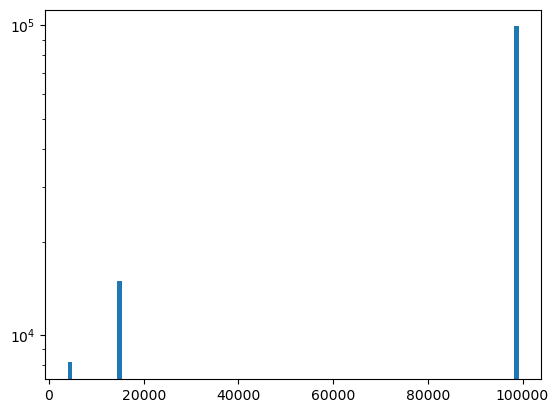

In [34]:
plt.hist(concatenated_df['num_in_file_in_star'], bins=100)
plt.yscale("log")

(array([  99.,  425., 4325.,  327.,  381.,  604., 1182.,  644.,   27.,
         150.]),
 array([-4.  , -3.55, -3.1 , -2.65, -2.2 , -1.75, -1.3 , -0.85, -0.4 ,
         0.05,  0.5 ]),
 <BarContainer object of 10 artists>)

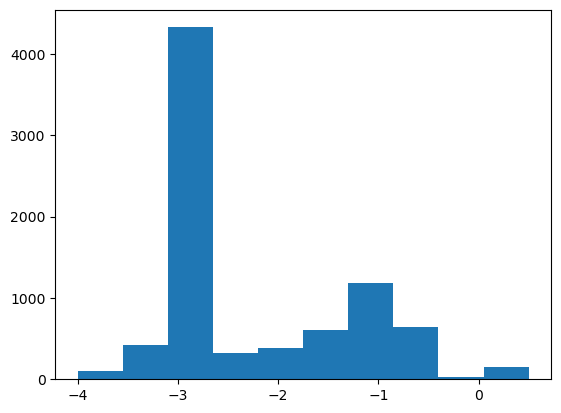

In [35]:
plt.hist(concatenated_df[concatenated_df['num_in_file_in_star']<10000]['Diff'])

In [43]:
index=0
direcname = '1020jan26'
path_new = '/lustre/lrspec/ZTF_data/science_extractions/'+direcname+'/'
pred_new = df.loc[index]["filename"]
extra = '_extraction_predsarray_'+str(df.loc[index,'quad'])+'_predsarray.npy'
# print(path+pred+extra)
predsarray_new = np.load(path_new+pred_new+extra)
posneg = df.loc[index, 'type']
nrow, ncol = 3080, 3072
wid=10
if posneg=='pos':
    
    predsarray = predsarray_new[:,1]
elif posneg=='neg':
    predsarray = predsarray_new[:,2]
else:
    print("POSNEG ISSUE")
pimg_new = predsarray.reshape(ncol - 2 * wid, nrow - 2 * wid)

In [45]:
index=0
direcname = '1020'
path_old = '/lustre/lrspec/ZTF_data/science_extractions/'+direcname+'/'
pred_old = df.loc[index]["filename"]
extra = '_extraction_predsarray_'+str(df.loc[index,'quad'])+'_predsarray.npy'
# print(path+pred+extra)
predsarray_old = np.load(path_old+pred_old+extra)
posneg = df.loc[index, 'type']
nrow, ncol = 3080, 3072
wid=10
if posneg=='pos':
    
    predsarray = predsarray_old[:,1]
elif posneg=='neg':
    predsarray = predsarray_old[:,2]
else:
    print("POSNEG ISSUE")
pimg_old = predsarray.reshape(ncol - 2 * wid, nrow - 2 * wid)

Text(0.5, 1.0, 'New')

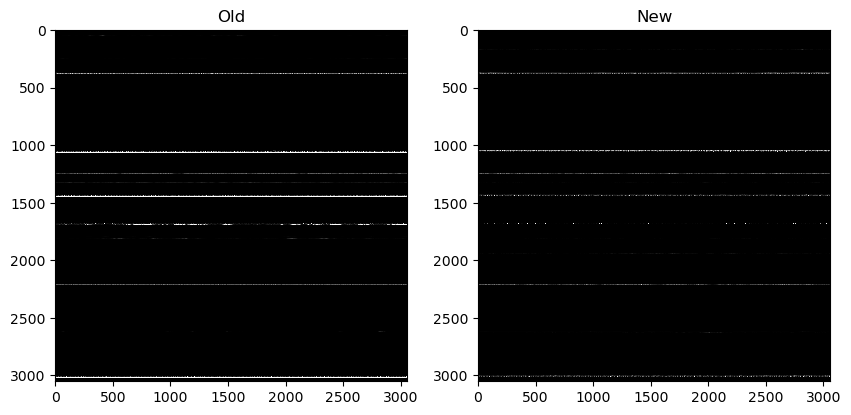

In [52]:
fig, ax = plt.subplots(1,2)
ax[0].imshow(pimg_old)
ax[1].imshow(pimg_new)
ax[0].set_title("Old")
ax[1].set_title("New")

Text(0.5, 1.0, 'New')

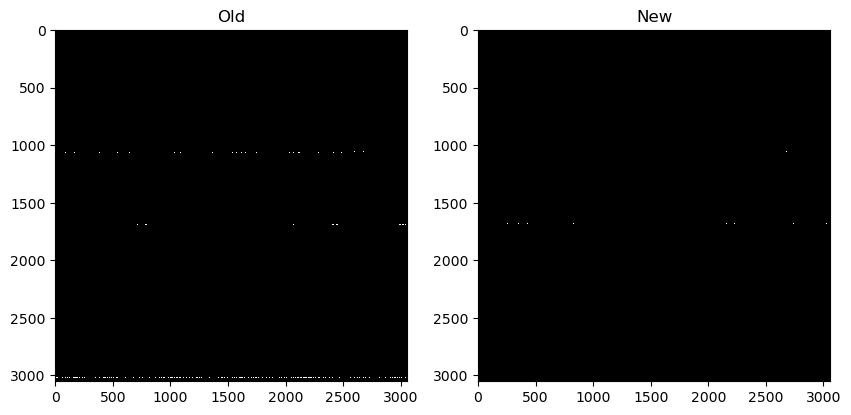

In [53]:
fig, ax = plt.subplots(1,2)
ax[0].imshow(pimg_old>.9999)
ax[1].imshow(pimg_new>.9999)
ax[0].set_title("Old")
ax[1].set_title("New")

In [6]:
concatenated_df

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quad
0,0,ztf_20221020157697_000640_zi_c08_x_0015.,pos,9.000000,2454.000000,5,2
1,1,ztf_20221020157697_000640_zi_c08_x_0015.,pos,32.000000,2454.000000,11,2
2,2,ztf_20221020157697_000640_zi_c08_x_0015.,pos,48.000000,2454.000000,7,2
3,3,ztf_20221020157697_000640_zi_c08_x_0015.,pos,72.500000,2454.000000,6,2
4,4,ztf_20221020157697_000640_zi_c08_x_0015.,pos,91.000000,2454.000000,9,2
...,...,...,...,...,...,...,...
30252,560,ztf_20221020148032_000686_zg_c10_x_0003.,both,2981.000000,2916.000000,1,2
30253,561,ztf_20221020148032_000686_zg_c10_x_0003.,both,2986.000000,1092.000000,19,2
30254,562,ztf_20221020148032_000686_zg_c10_x_0003.,both,3000.500000,1092.000000,2,2
30255,563,ztf_20221020148032_000686_zg_c10_x_0003.,both,3014.363636,1092.272727,11,2


In [4]:
rff.match_stars_eff(df)

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quad,closest_x,closest_y,Diff,brightness_ranking
0,0,ztf_20221020157697_000640_zi_c08_x_0015.,pos,9.000000,2454.000000,5,2,2564.0,2513.0,100.000000,3.0
1,1,ztf_20221020157697_000640_zi_c08_x_0015.,pos,32.000000,2454.000000,11,2,2564.0,2513.0,100.000000,3.0
2,2,ztf_20221020157697_000640_zi_c08_x_0015.,pos,48.000000,2454.000000,7,2,2564.0,2513.0,100.000000,3.0
3,3,ztf_20221020157697_000640_zi_c08_x_0015.,pos,72.500000,2454.000000,6,2,2564.0,2513.0,100.000000,3.0
4,4,ztf_20221020157697_000640_zi_c08_x_0015.,pos,91.000000,2454.000000,9,2,2564.0,2513.0,100.000000,3.0
...,...,...,...,...,...,...,...,...,...,...,...
588,588,ztf_20221020157697_000640_zi_c08_x_0015.,both,2984.722222,2451.500000,18,2,2564.0,2513.0,102.500000,3.0
589,589,ztf_20221020157697_000640_zi_c08_x_0015.,both,3012.500000,2453.000000,4,2,2564.0,2513.0,101.000000,3.0
590,590,ztf_20221020157697_000640_zi_c08_x_0015.,both,3022.966667,2451.733333,30,2,2564.0,2513.0,102.266667,3.0
591,591,ztf_20221020157697_000640_zi_c08_x_0015.,both,3034.500000,2453.000000,4,2,2564.0,2513.0,101.000000,3.0


In [23]:
df2 = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020jan26/ztf_20221020157697_000640_zi_c08_x_0015._2_alllist')

In [24]:
df2

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quad
0,0,ztf_20221020157697_000640_zi_c08_x_0015.,pos,9.000000,2454.000000,5,2
1,1,ztf_20221020157697_000640_zi_c08_x_0015.,pos,32.000000,2454.000000,11,2
2,2,ztf_20221020157697_000640_zi_c08_x_0015.,pos,48.000000,2454.000000,7,2
3,3,ztf_20221020157697_000640_zi_c08_x_0015.,pos,72.500000,2454.000000,6,2
4,4,ztf_20221020157697_000640_zi_c08_x_0015.,pos,91.000000,2454.000000,9,2
...,...,...,...,...,...,...,...
588,588,ztf_20221020157697_000640_zi_c08_x_0015.,both,2984.722222,2451.500000,18,2
589,589,ztf_20221020157697_000640_zi_c08_x_0015.,both,3012.500000,2453.000000,4,2
590,590,ztf_20221020157697_000640_zi_c08_x_0015.,both,3022.966667,2451.733333,30,2
591,591,ztf_20221020157697_000640_zi_c08_x_0015.,both,3034.500000,2453.000000,4,2
